
# Klasifikasi 200 Berita Detik: TF-IDF vs Skip-Gram + Naive Bayes

## Tujuan Utama

Notebook ini dibuat untuk memenuhi tahapan tugas:

1. Melakukan preprocessing terhadap 200 berita.
2. Membandingkan klasifikasi menggunakan **TF-IDF** dan **Skip-Gram**.
3. Menggunakan **Naive Bayes** sebagai algoritma klasifikasi.
4. Membandingkan ukuran/shape matriks representasi TF-IDF dan Skip-Gram.
5. Melakukan **Grid Search Hyperparameter Tuning** untuk Skip-Gram + Naive Bayes.
6. Menentukan kombinasi hyperparameter terbaik.
7. Menyimpan model Skip-Gram dan Naive Bayes dalam format `.pkl`.
8. Menyiapkan model yang nantinya dapat digunakan untuk aplikasi klasifikasi berita berbasis link menggunakan Streamlit/Flask.

> **Catatan penting:** Skip-Gram adalah metode WAJIB dalam tugas ini. Pada notebook ini Skip-Gram dibuat menggunakan `Word2Vec` dengan parameter `sg=1`.



## Alur Penelitian

```text
Dataset 200 Berita
        ↓
Pengecekan Data
        ↓
Preprocessing
(Case Folding → Cleaning → Stopword → Stemming → Tokenisasi)
        ↓
Train-Test Split
        ↓
 ┌───────────────┬─────────────────┐
 ↓               ↓
TF-IDF        Skip-Gram
 ↓               ↓
Naive Bayes   Word2Vec (sg=1)
 ↓               ↓
Evaluasi      Document Vector
 ↓               ↓
 └───────┬───────┘
         ↓
Perbandingan Model
         ↓
Perbandingan Ukuran Matriks
         ↓
Grid Search
         ↓
Hyperparameter Terbaik
         ↓
Model Final
         ↓
Simpan .pkl
```


## 1. Instalasi Library

Tujuan: memasang library yang dibutuhkan untuk preprocessing bahasa Indonesia, ekstraksi fitur, Skip-Gram, Naive Bayes, evaluasi, dan visualisasi.

In [ ]:
!pip install Sastrawi gensim scikit-learn pandas numpy matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 64.6 MB/s eta 0:00:00


## 2. Import Library

Tujuan utama dari sekumpulan kode tersebut adalah untuk mempersiapkan alur kerja lengkap pemodelan *Natural Language Processing* (NLP) atau klasifikasi teks berbahasa Indonesia, mulai dari pra-pemrosesan data hingga evaluasi model. Pustaka yang diimpor mencakup alat untuk manipulasi data (`pandas`, `numpy`), pembersihan teks khusus bahasa Indonesia (`Sastrawi`, `re`), ekstraksi kata menjadi vektor matematika (`TfidfVectorizer`, `Word2Vec`), dan algoritma *Machine Learning* menggunakan *Naive Bayes* (`MultinomialNB`). Selain itu, skrip ini juga menyiapkan metrik evaluasi dari `sklearn` untuk mengukur akurasi prediksi, fitur untuk menyimpan model yang sudah dilatih (`pickle`), serta pustaka visualisasi (`matplotlib`, `seaborn`) untuk mempresentasikan hasil analisis secara grafis di lingkungan Google Colab.

In [ ]:

import pandas as pd
import numpy as np
import re
import os
import pickle

from google.colab import files

from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from gensim.models import Word2Vec

import matplotlib.pyplot as plt
import seaborn as sns


## 3. Upload Dataset

Tujuan: memasukkan file `dataset_detik_200_berita.csv` ke Google Colab.

In [ ]:

uploaded = files.upload()


Saving dataset_detik_200_berita.csv to dataset_detik_200_berita.csv


## 4. Membaca Dataset

Tujuan utama dari kode tersebut adalah untuk memuat dan memeriksa dataset awal yang akan digunakan dalam proyek. Menggunakan pustaka `pandas`, skrip ini membaca sebuah file CSV bernama "dataset_detik_200_berita.csv" menggunakan tanda titik koma (`sep=";"`) sebagai pemisah antar kolomnya, kemudian menyimpannya ke dalam struktur tabel atau *DataFrame* (`df`). Terakhir, perintah `display(df.head(5))` digunakan untuk menampilkan lima baris pertama dari data tersebut ke layar, sehingga pengguna dapat memverifikasi secara visual bahwa data telah berhasil diimpor dan terformat dengan benar sebelum diproses lebih lanjut.

In [ ]:
# ==========================================
# CELL - MEMBACA CSV
# ==========================================

import pandas as pd

DATA_PATH = "dataset_detik_200_berita.csv"

df = pd.read_csv(
    DATA_PATH,
    sep=";",
    engine="python"
)

display(df.head(5))

,id,isi_berita,label
0,1,Men's World Tennis Championship 2026 sudah mem...,sport
1,2,Barra Ghaisan Zeinatma menunjukkan perkembanga...,sport
2,3,Marco Bezzecchi tak sabar menghadapi MotoGP Sa...,sport
3,4,Marc Marquez masih harus beradaptasi dengan ko...,sport
4,5,Pebalap Mercedes GP Kimi Antonelli tampil luar...,sport


## 5. Pengecekan Missing Value dan Duplikat

Tujuan utama dari kode tersebut adalah untuk melakukan pemeriksaan awal terhadap kualitas dan kebersihan dataset (*data quality check*) sebelum diproses lebih lanjut. Skrip ini secara spesifik menghitung dan menampilkan jumlah data yang kosong (*missing value*) pada kolom teks berita ("isi_berita") dan kategori sasarannya ("label"), serta mendeteksi jumlah data yang ganda atau duplikat baik berdasarkan kesamaan isi berita maupun nomor identitas (`id`) uniknya. Langkah diagnostik ini sangat penting untuk mengidentifikasi kecacatan atau redundansi pada data yang nantinya perlu dibersihkan agar tidak merusak akurasi model *Machine Learning* yang akan dilatih.

In [ ]:

print("Pengecekan Dataset")
print("=" * 50)

print("\nJumlah Missing Value:")
print(df[["isi_berita", "label"]].isnull().sum())

print("\nJumlah Duplikat Isi Berita:")
print(df.duplicated(subset=["isi_berita"]).sum())

print("\nJumlah Duplikat ID:")
print(df["id"].duplicated().sum())


Pengecekan Dataset

Jumlah Missing Value:
isi_berita    0
label         0
dtype: int64

Jumlah Duplikat Isi Berita:
0

Jumlah Duplikat ID:
0


## 6. Preprocessing Teks

Tujuan: mengubah berita mentah menjadi teks yang lebih terstruktur dan siap digunakan sebagai fitur.

Tahapan:
- **Case Folding:** mengubah huruf menjadi lowercase.
- **Cleaning:** menghapus tanda baca, karakter khusus, angka, dan spasi berlebih.
- **Stopword Removal:** menghapus kata umum menggunakan Sastrawi.
- **Stemming:** mengubah kata ke bentuk dasar menggunakan Sastrawi.
- **Tokenisasi:** memecah teks menjadi daftar kata.

Kolom `label` tidak diproses karena merupakan target klasifikasi.

In [ ]:

# 1. Case Folding
df["case_folding"] = df["isi_berita"].astype(str).str.lower()

# 2. Cleaning
df["clean_text"] = df["case_folding"].apply(
    lambda x: re.sub(r"[^\w\s]", " ", x)
)

df["clean_text"] = df["clean_text"].apply(
    lambda x: re.sub(r"\d+", " ", x)
)

df["clean_text"] = df["clean_text"].apply(
    lambda x: re.sub(r"\s+", " ", x).strip()
)

# 3. Stopword Removal
stop_factory = StopWordRemoverFactory()
stopword_remover = stop_factory.create_stop_word_remover()

df["text_no_stopword"] = df["clean_text"].apply(
    lambda x: stopword_remover.remove(x)
)

# 4. Stemming
stem_factory = StemmerFactory()
stemmer = stem_factory.create_stemmer()

df["text_stemmed"] = df["text_no_stopword"].apply(
    lambda x: stemmer.stem(x)
)

# 5. Tokenisasi
df["tokens_stemmed"] = df["text_stemmed"].apply(
    lambda x: x.split()
)

display(
    df[
        [
            "isi_berita",
            "label",
            "case_folding",
            "clean_text",
            "text_no_stopword",
            "text_stemmed",
            "tokens_stemmed"
        ]
    ].head(5)
)


,isi_berita,label,case_folding,clean_text,text_no_stopword,text_stemmed,tokens_stemmed
0,Men's World Tennis Championship 2026 sudah mem...,sport,men's world tennis championship 2026 sudah mem...,men s world tennis championship sudah memasuki...,men s world tennis championship memasuki seri ...,men s world tennis championship pasuk seri v s...,"[men, s, world, tennis, championship, pasuk, s..."
1,Barra Ghaisan Zeinatma menunjukkan perkembanga...,sport,barra ghaisan zeinatma menunjukkan perkembanga...,barra ghaisan zeinatma menunjukkan perkembanga...,barra ghaisan zeinatma menunjukkan perkembanga...,barra ghaisan zeinatma tunjuk kembang positif ...,"[barra, ghaisan, zeinatma, tunjuk, kembang, po..."
2,Marco Bezzecchi tak sabar menghadapi MotoGP Sa...,sport,marco bezzecchi tak sabar menghadapi motogp sa...,marco bezzecchi tak sabar menghadapi motogp sa...,marco bezzecchi tak sabar menghadapi motogp sa...,marco bezzecchi tak sabar hadap motogp san mar...,"[marco, bezzecchi, tak, sabar, hadap, motogp, ..."
3,Marc Marquez masih harus beradaptasi dengan ko...,sport,marc marquez masih harus beradaptasi dengan ko...,marc marquez masih harus beradaptasi dengan ko...,marc marquez harus beradaptasi kondisi lengan ...,marc marquez harus adaptasi kondisi lengan kan...,"[marc, marquez, harus, adaptasi, kondisi, leng..."
4,Pebalap Mercedes GP Kimi Antonelli tampil luar...,sport,pebalap mercedes gp kimi antonelli tampil luar...,pebalap mercedes gp kimi antonelli tampil luar...,pebalap mercedes gp kimi antonelli tampil luar...,balap mercedes gp kim antonelli tampil luar bi...,"[balap, mercedes, gp, kim, antonelli, tampil, ..."


## 7. Distribusi Label

Tujuan: mengetahui jumlah kategori berita dan melihat apakah distribusi kelas relatif seimbang.

In [ ]:

print("Distribusi Label Berita")
print("=" * 50)

print(df["label"].value_counts())

print("\nJumlah kelas:", df["label"].nunique())


Distribusi Label Berita
label
sport      100
finance    100
Name: count, dtype: int64

Jumlah kelas: 2


## 8. Visualisasi Distribusi Label

Tujuan: memperlihatkan distribusi jumlah berita pada setiap kategori secara visual.

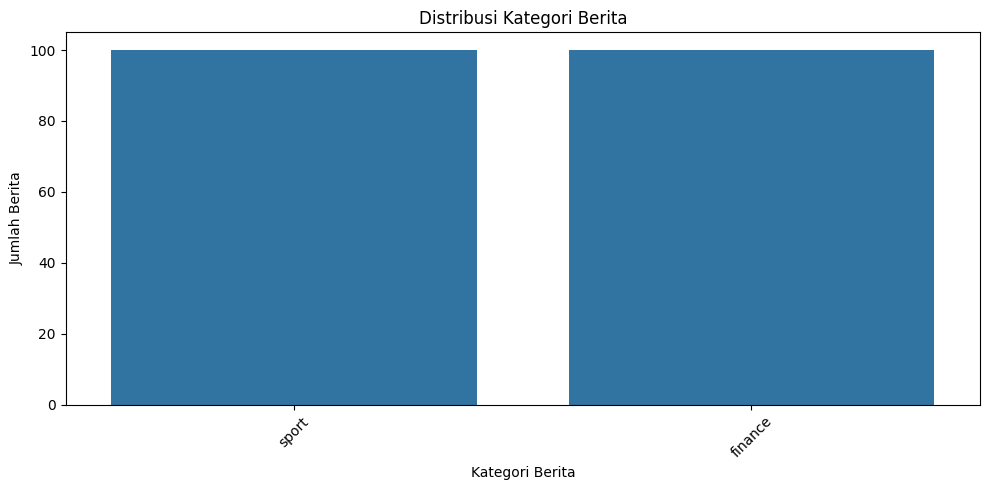

In [ ]:

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="label",
    order=df["label"].value_counts().index
)

plt.title("Distribusi Kategori Berita")
plt.xlabel("Kategori Berita")
plt.ylabel("Jumlah Berita")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


## 9. Menentukan X dan y

Tujuan: menentukan data input dan target.

- `X` = `text_stemmed`, yaitu teks berita setelah preprocessing.
- `y` = `label`, yaitu kategori berita yang akan diprediksi.

In [ ]:

X = df["text_stemmed"].astype(str)
y = df["label"].astype(str)

print("Jumlah data X:", len(X))
print("Jumlah data y:", len(y))

print("\nContoh X:")
print(X.iloc[0][:500])

print("\nContoh y:")
print(y.iloc[0])


Jumlah data X: 200
Jumlah data y: 200

Contoh X:
men s world tennis championship pasuk seri v sayang tiga tenis tuan rumah gagal laju babak utama putar final kualifikasi seri v m men s world tennis championship senin indonesia turun tiga wakil ethan jake frans ethan david zapp kareem abdul hakim tiga malah gagal tuntas misi lolos babak utama turnamen hadiah total ribu dolar as total tenis negara tampil babak kualifikasi tanding lapang a bal beach country club nusa ethan baru raya ulang tahun tumbang unggul empat shanker heisnam ethan akhir pek

Contoh y:
sport


## 10. Train-Test Split

Tujuan: membagi data menjadi data training dan testing. Digunakan 80% training dan 20% testing. `stratify=y` menjaga proporsi kelas agar tetap representatif.

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data:")
print("Training :", len(X_train))
print("Testing  :", len(X_test))

print("\nDistribusi label training:")
print(y_train.value_counts())

print("\nDistribusi label testing:")
print(y_test.value_counts())


Jumlah data:
Training : 160
Testing  : 40

Distribusi label training:
label
finance    80
sport      80
Name: count, dtype: int64

Distribusi label testing:
label
finance    20
sport      20
Name: count, dtype: int64


## 11. Metode 1 — TF-IDF

Tujuan: mengubah dokumen menjadi matriks numerik berdasarkan bobot Term Frequency-Inverse Document Frequency.

`fit_transform()` hanya dilakukan pada data training untuk mencegah kebocoran informasi dari data testing.

In [ ]:

tfidf_vectorizer = TfidfVectorizer()

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Ukuran matriks TF-IDF Training:", X_train_tfidf.shape)
print("Ukuran matriks TF-IDF Testing :", X_test_tfidf.shape)

print(
    "\nJumlah fitur/kata:",
    len(tfidf_vectorizer.get_feature_names_out())
)


Ukuran matriks TF-IDF Training: (160, 4476)
Ukuran matriks TF-IDF Testing : (40, 4476)

Jumlah fitur/kata: 4476


## 12. TF-IDF + Naive Bayes

Tujuan utama dari kode tersebut adalah untuk melatih (*training*) model *Machine Learning* dan melakukan prediksi menggunakan algoritma Multinomial Naive Bayes. Model ini awalnya diinisialisasi, kemudian dilatih (`fit`) untuk mengenali pola menggunakan data latih yang teksnya telah diubah menjadi representasi angka melalui metode TF-IDF (`X_train_tfidf`) beserta label sasarannya (`y_train`). Setelah proses pembelajaran selesai, model tersebut langsung diaplikasikan untuk memprediksi (`predict`) kategori dari sekumpulan data uji baru (`X_test_tfidf`), dan hasil tebakannya disimpan ke dalam variabel `y_pred_tfidf` agar nantinya dapat dievaluasi tingkat keakuratannya.

In [ ]:

nb_tfidf = MultinomialNB()

nb_tfidf.fit(
    X_train_tfidf,
    y_train
)

y_pred_tfidf = nb_tfidf.predict(X_test_tfidf)

print("Training TF-IDF + Naive Bayes selesai.")


Training TF-IDF + Naive Bayes selesai.


## 13. Evaluasi TF-IDF + Naive Bayes

Tujuan: mengukur performa model menggunakan Accuracy, Precision, Recall, dan F1-Score.

In [ ]:

accuracy_tfidf = accuracy_score(y_test, y_pred_tfidf)
precision_tfidf = precision_score(
    y_test, y_pred_tfidf,
    average="weighted",
    zero_division=0
)
recall_tfidf = recall_score(
    y_test, y_pred_tfidf,
    average="weighted",
    zero_division=0
)
f1_tfidf = f1_score(
    y_test, y_pred_tfidf,
    average="weighted",
    zero_division=0
)

print("HASIL EVALUASI TF-IDF + NAIVE BAYES")
print("=" * 50)
print("Accuracy :", accuracy_tfidf)
print("Precision:", precision_tfidf)
print("Recall   :", recall_tfidf)
print("F1-Score :", f1_tfidf)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tfidf,
    zero_division=0
))


HASIL EVALUASI TF-IDF + NAIVE BAYES
Accuracy : 0.975
Precision: 0.9761904761904763
Recall   : 0.975
F1-Score : 0.9749843652282676

Classification Report:
              precision    recall  f1-score   support

     finance       0.95      1.00      0.98        20
       sport       1.00      0.95      0.97        20

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40



## 14. Confusion Matrix TF-IDF

Tujuan: melihat jumlah prediksi benar dan salah untuk setiap kelas.

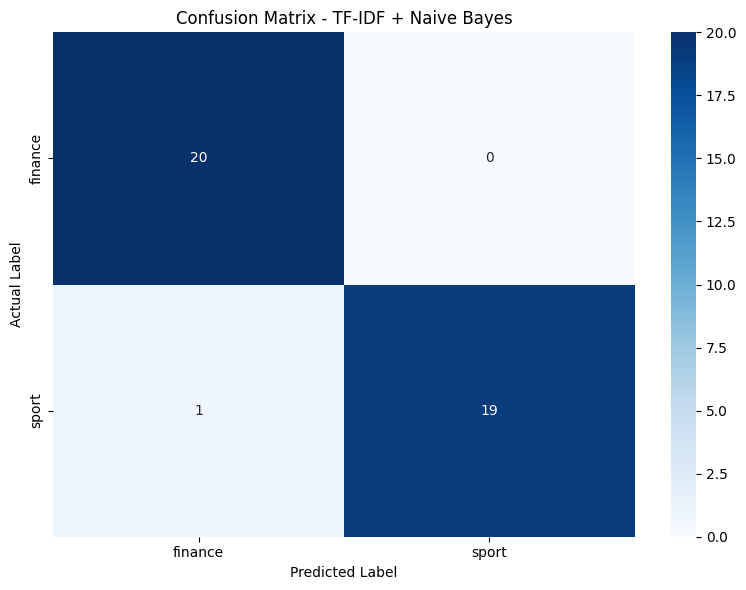

In [ ]:

cm_tfidf = confusion_matrix(y_test, y_pred_tfidf)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_tfidf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nb_tfidf.classes_,
    yticklabels=nb_tfidf.classes_
)

plt.title("Confusion Matrix - TF-IDF + Naive Bayes")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()


## 15. Metode 2 — Skip-Gram

Tujuan utama dari kode tersebut adalah untuk mengekstrak dan memisahkan teks yang telah dipraproses (berupa *token* atau kata-kata dasar) ke dalam kelompok data latih (*training*) dan data uji (*testing*) berdasarkan indeks pembagian yang sudah dilakukan sebelumnya. Dengan mengambil data dari kolom `"tokens_stemmed"` pada *DataFrame* utama dan mengubahnya menjadi format *list* (daftar), kode ini menyiapkan struktur data yang tepat untuk pemodelan lebih lanjut, khususnya bagi algoritma yang membutuhkan input berupa kumpulan urutan kata (seperti *Word2Vec*). Selain itu, perintah cetak (*print*) pada akhir kode berfungsi sebagai langkah validasi visual untuk memastikan bahwa jumlah dokumen sesuai dan bentuk *token* sudah benar sebelum dimasukkan ke dalam model.

In [ ]:

train_indices = X_train.index
test_indices = X_test.index

tokens_train = df.loc[
    train_indices,
    "tokens_stemmed"
].tolist()

tokens_test = df.loc[
    test_indices,
    "tokens_stemmed"
].tolist()

print("Jumlah dokumen training:", len(tokens_train))
print("Jumlah dokumen testing :", len(tokens_test))

print("\nContoh token:")
print(tokens_train[0][:20])


Jumlah dokumen training: 160
Jumlah dokumen testing : 40

Contoh token:
['pt', 'asuransi', 'tugu', 'pratama', 'indonesia', 'tbk', 'tugu', 'insurance', 'terus', 'kuat', 'kualitas', 'layan', 'alam', 'langgan', 'bagi', 'transformasi', 'usaha', 'berkat', 'konsistensi', 'sebut']


## 16. Training Skip-Gram

Parameter awal:
- `vector_size=100`: setiap kata direpresentasikan sebagai vector 100 dimensi.
- `window=5`: konteks diambil dalam jendela 5 kata.
- `min_count=1`: kata dengan frekuensi minimal 1 tetap digunakan.
- `sg=1`: **mengaktifkan Skip-Gram**.
- `epochs=20`: jumlah iterasi training.

In [ ]:

skipgram_model = Word2Vec(
    sentences=tokens_train,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=1,
    epochs=20,
    seed=42
)

print("Training Skip-Gram selesai.")
print("Jumlah kata dalam vocabulary:", len(skipgram_model.wv))
print("Ukuran vector:", skipgram_model.vector_size)


Training Skip-Gram selesai.
Jumlah kata dalam vocabulary: 4496
Ukuran vector: 100


## 17. Membuat Document Vector dari Skip-Gram

Tujuan utama dari kode tersebut adalah untuk mengubah keseluruhan teks atau dokumen menjadi sebuah representasi vektor tunggal (deretan angka) menggunakan model *Word2Vec* tipe *Skip-Gram*. Melalui fungsi `document_vector`, skrip ini mengekstrak nilai vektor dari setiap kata di dalam satu dokumen, lalu menghitung nilai rata-ratanya (`np.mean`) agar makna keseluruhan dari kumpulan kata tersebut dapat dirangkum ke dalam satu vektor padat. Proses ini diterapkan pada data latih maupun data uji untuk menghasilkan matriks fitur numerik (`X_train_skipgram` dan `X_test_skipgram`) yang sudah siap digunakan sebagai data masukan bagi algoritma *Machine Learning* untuk proses klasifikasi.

In [ ]:

def document_vector(model, tokens):
    vectors = []

    for word in tokens:
        if word in model.wv:
            vectors.append(model.wv[word])

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


X_train_skipgram = np.array([
    document_vector(skipgram_model, tokens)
    for tokens in tokens_train
])

X_test_skipgram = np.array([
    document_vector(skipgram_model, tokens)
    for tokens in tokens_test
])

print("Ukuran matriks Skip-Gram Training:", X_train_skipgram.shape)
print("Ukuran matriks Skip-Gram Testing :", X_test_skipgram.shape)


Ukuran matriks Skip-Gram Training: (160, 100)
Ukuran matriks Skip-Gram Testing : (40, 100)


## 18. Scaling Vector Skip-Gram

Tujuan utama dari kode tersebut adalah untuk melakukan normalisasi atau penskalaan (*scaling*) pada nilai matriks fitur Skip-Gram agar berada dalam rentang angka yang seragam (biasanya antara 0 hingga 1) menggunakan `MinMaxScaler`. Langkah ini sangat krusial dalam alur kerja ini karena algoritma *Multinomial Naive Bayes* tidak dapat memproses data masukan yang memiliki nilai negatif, yang mana sering kali dihasilkan oleh ekstraksi vektor dari *Word2Vec*. Dengan menerapkan proses penskalaan ini pada data latih dan data uji, skrip ini memastikan seluruh representasi numerik teks bernilai positif atau nol, sehingga model klasifikasi dapat berjalan tanpa *error* dan bekerja lebih stabil.

In [ ]:

scaler_skipgram = MinMaxScaler()

X_train_skipgram_scaled = scaler_skipgram.fit_transform(
    X_train_skipgram
)

X_test_skipgram_scaled = scaler_skipgram.transform(
    X_test_skipgram
)

print("Scaling Skip-Gram selesai.")
print("Nilai minimum training:", X_train_skipgram_scaled.min())
print("Nilai maksimum training:", X_train_skipgram_scaled.max())


Scaling Skip-Gram selesai.
Nilai minimum training: 0.0
Nilai maksimum training: 1.0000001


## 19. Skip-Gram + Naive Bayes

Tujuan utama dari kode tersebut adalah untuk melatih (*training*) model *Machine Learning* dan melakukan prediksi menggunakan algoritma *Multinomial Naive Bayes*, namun kali ini diaplikasikan pada representasi teks yang dihasilkan oleh *Word2Vec Skip-Gram*. Model dilatih (`fit`) untuk mempelajari pola klasifikasi berdasarkan data latih Skip-Gram yang sebelumnya telah dinormalisasi menjadi nilai positif (`X_train_skipgram_scaled`) beserta label sasarannya (`y_train`). Setelah proses pembelajaran tersebut selesai, model langsung digunakan untuk menebak atau memprediksi (`predict`) kategori dari sekumpulan data uji (`X_test_skipgram_scaled`), dan hasil tebakannya disimpan ke dalam variabel `y_pred_skipgram` agar nantinya dapat diukur tingkat keakuratannya pada tahap evaluasi.

In [ ]:

nb_skipgram = MultinomialNB()

nb_skipgram.fit(
    X_train_skipgram_scaled,
    y_train
)

y_pred_skipgram = nb_skipgram.predict(
    X_test_skipgram_scaled
)

print("Training Skip-Gram + Naive Bayes selesai.")


Training Skip-Gram + Naive Bayes selesai.


## 20. Evaluasi Skip-Gram + Naive Bayes

Tujuan utama dari kode tersebut adalah untuk mengevaluasi performa model *Multinomial Naive Bayes* yang telah dilatih menggunakan fitur *Word2Vec Skip-Gram*. Skrip ini membandingkan hasil tebakan model (`y_pred_skipgram`) dengan label data uji yang sebenarnya (`y_test`) untuk menghitung metrik evaluasi utama secara menyeluruh, yaitu tingkat *Accuracy* (akurasi keseluruhan), *Precision* (ketepatan prediksi positif), *Recall* (kemampuan menemukan semua data positif), dan *F1-Score* (keseimbangan presisi dan *recall*). Selain metrik rata-rata tertimbang (*weighted average*), kode ini juga menampilkan `classification_report` untuk memberikan rincian detail performa model pada masing-masing kategori atau kelas agar pengguna dapat mengetahui di kategori mana model sudah bekerja dengan baik atau masih sering salah.

In [ ]:

accuracy_skipgram = accuracy_score(y_test, y_pred_skipgram)
precision_skipgram = precision_score(
    y_test, y_pred_skipgram,
    average="weighted",
    zero_division=0
)
recall_skipgram = recall_score(
    y_test, y_pred_skipgram,
    average="weighted",
    zero_division=0
)
f1_skipgram = f1_score(
    y_test, y_pred_skipgram,
    average="weighted",
    zero_division=0
)

print("HASIL EVALUASI SKIP-GRAM + NAIVE BAYES")
print("=" * 50)
print("Accuracy :", accuracy_skipgram)
print("Precision:", precision_skipgram)
print("Recall   :", recall_skipgram)
print("F1-Score :", f1_skipgram)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_skipgram,
    zero_division=0
))


HASIL EVALUASI SKIP-GRAM + NAIVE BAYES
Accuracy : 0.925
Precision: 0.9347826086956521
Recall   : 0.925
F1-Score : 0.9245757385292268

Classification Report:
              precision    recall  f1-score   support

     finance       0.87      1.00      0.93        20
       sport       1.00      0.85      0.92        20

    accuracy                           0.93        40
   macro avg       0.93      0.93      0.92        40
weighted avg       0.93      0.93      0.92        40



## 21. Confusion Matrix Skip-Gram

Tujuan: melihat distribusi prediksi benar dan salah untuk setiap kategori pada model Skip-Gram.

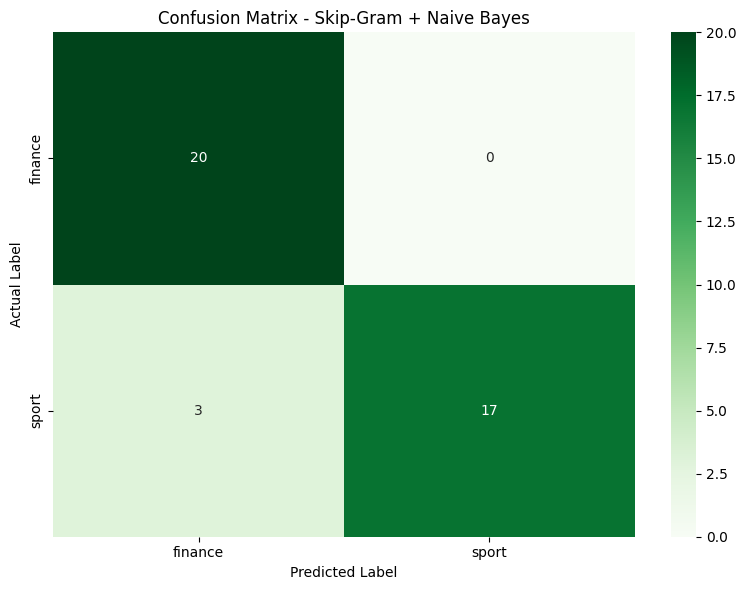

In [ ]:

cm_skipgram = confusion_matrix(y_test, y_pred_skipgram)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_skipgram,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=nb_skipgram.classes_,
    yticklabels=nb_skipgram.classes_
)

plt.title("Confusion Matrix - Skip-Gram + Naive Bayes")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()


## 22. Perbandingan Performa TF-IDF vs Skip-Gram

Tujuan: membandingkan kedua representasi fitur dengan algoritma klasifikasi yang sama, yaitu Naive Bayes.

In [ ]:

hasil_perbandingan = pd.DataFrame({
    "Metode": [
        "TF-IDF + Naive Bayes",
        "Skip-Gram + Naive Bayes"
    ],
    "Accuracy": [
        accuracy_tfidf,
        accuracy_skipgram
    ],
    "Precision": [
        precision_tfidf,
        precision_skipgram
    ],
    "Recall": [
        recall_tfidf,
        recall_skipgram
    ],
    "F1-Score": [
        f1_tfidf,
        f1_skipgram
    ]
})

display(hasil_perbandingan)


,Metode,Accuracy,Precision,Recall,F1-Score
0,TF-IDF + Naive Bayes,0.975,0.976190,0.975,0.974984
1,Skip-Gram + Naive Bayes,0.925,0.934783,0.925,0.924576


## 23. Perbandingan Ukuran Space / Matriks

Tujuan: membandingkan ukuran representasi data pada TF-IDF dan Skip-Gram.

- TF-IDF berbentuk `jumlah dokumen × jumlah fitur/kata`.
- Document vector Skip-Gram berbentuk `jumlah dokumen × ukuran vector`.
- Matriks embedding Word2Vec berbentuk `jumlah vocabulary × ukuran vector`.

In [ ]:

print("PERBANDINGAN UKURAN SPACE")
print("=" * 50)

print("TF-IDF")
print("Training :", X_train_tfidf.shape)
print("Testing  :", X_test_tfidf.shape)

print("\nSkip-Gram Document Vector")
print("Training :", X_train_skipgram.shape)
print("Testing  :", X_test_skipgram.shape)

print("\nSkip-Gram Word Embedding Matrix")
print(skipgram_model.wv.vectors.shape)


PERBANDINGAN UKURAN SPACE
TF-IDF
Training : (160, 4476)
Testing  : (40, 4476)

Skip-Gram Document Vector
Training : (160, 100)
Testing  : (40, 100)

Skip-Gram Word Embedding Matrix
(4496, 100)


## 24. Grid Search Hyperparameter

Tujuan: mencoba beberapa kombinasi hyperparameter untuk menemukan konfigurasi Skip-Gram + Naive Bayes yang memberikan performa terbaik.

Parameter Skip-Gram yang diuji:
- `vector_size`
- `window`
- `min_count`
- `epochs`

Parameter Naive Bayes yang diuji:
- `alpha`

Karena dataset hanya 200 berita, grid dibuat relatif kecil agar waktu komputasi tetap masuk akal.

In [ ]:

param_grid = {
    "vector_size": [50, 100],
    "window": [3, 5],
    "min_count": [1],
    "epochs": [10, 20],
    "alpha": [0.1, 0.5, 1.0]
}

grid = list(ParameterGrid(param_grid))

print("Jumlah kombinasi parameter:", len(grid))


Jumlah kombinasi parameter: 24


## 25. Menjalankan Grid Search

Tujuan utama dari kode tersebut adalah untuk melakukan *hyperparameter tuning* (pencarian konfigurasi optimal) secara otomatis menggunakan metode *Grid Search* untuk kombinasi model *Word2Vec Skip-Gram* dan *Multinomial Naive Bayes*. Melalui proses iterasi yang berulang, skrip ini melatih ulang model Word2Vec, mengekstrak dan menormalkan vektor teks, serta melatih model Naive Bayes menggunakan berbagai kombinasi nilai parameter yang berbeda-beda (seperti ukuran vektor, ukuran *window*, jumlah *epoch*, dan nilai *alpha*). Pada setiap akhir percobaan, performa dari kombinasi parameter tersebut diukur (menggunakan metrik *accuracy, precision, recall*, dan *f1-score*) lalu disimpan ke dalam daftar `hasil_grid` agar nantinya dapat dibandingkan untuk menemukan setelan mana yang menghasilkan tingkat prediksi paling akurat.

In [ ]:

hasil_grid = []

for i, params in enumerate(grid, start=1):

    print(
        f"Percobaan {i}/{len(grid)} | "
        f"vector_size={params['vector_size']}, "
        f"window={params['window']}, "
        f"min_count={params['min_count']}, "
        f"epochs={params['epochs']}, "
        f"alpha={params['alpha']}"
    )

    model = Word2Vec(
        sentences=tokens_train,
        vector_size=params["vector_size"],
        window=params["window"],
        min_count=params["min_count"],
        workers=4,
        sg=1,
        epochs=params["epochs"],
        seed=42
    )

    train_vectors = np.array([
        document_vector(model, tokens)
        for tokens in tokens_train
    ])

    test_vectors = np.array([
        document_vector(model, tokens)
        for tokens in tokens_test
    ])

    scaler = MinMaxScaler()
    train_scaled = scaler.fit_transform(train_vectors)
    test_scaled = scaler.transform(test_vectors)

    model_nb = MultinomialNB(alpha=params["alpha"])
    model_nb.fit(train_scaled, y_train)

    pred = model_nb.predict(test_scaled)

    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(
        y_test, pred,
        average="weighted",
        zero_division=0
    )
    recall = recall_score(
        y_test, pred,
        average="weighted",
        zero_division=0
    )
    f1 = f1_score(
        y_test, pred,
        average="weighted",
        zero_division=0
    )

    hasil_grid.append({
        "vector_size": params["vector_size"],
        "window": params["window"],
        "min_count": params["min_count"],
        "epochs": params["epochs"],
        "alpha": params["alpha"],
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    })

print("\nGrid Search selesai.")


Percobaan 1/24 | vector_size=50, window=3, min_count=1, epochs=10, alpha=0.1
Percobaan 2/24 | vector_size=50, window=5, min_count=1, epochs=10, alpha=0.1
Percobaan 3/24 | vector_size=100, window=3, min_count=1, epochs=10, alpha=0.1
Percobaan 4/24 | vector_size=100, window=5, min_count=1, epochs=10, alpha=0.1
Percobaan 5/24 | vector_size=50, window=3, min_count=1, epochs=20, alpha=0.1
Percobaan 6/24 | vector_size=50, window=5, min_count=1, epochs=20, alpha=0.1
Percobaan 7/24 | vector_size=100, window=3, min_count=1, epochs=20, alpha=0.1
Percobaan 8/24 | vector_size=100, window=5, min_count=1, epochs=20, alpha=0.1
Percobaan 9/24 | vector_size=50, window=3, min_count=1, epochs=10, alpha=0.5
Percobaan 10/24 | vector_size=50, window=5, min_count=1, epochs=10, alpha=0.5
Percobaan 11/24 | vector_size=100, window=3, min_count=1, epochs=10, alpha=0.5
Percobaan 12/24 | vector_size=100, window=5, min_count=1, epochs=10, alpha=0.5
Percobaan 13/24 | vector_size=50, window=3, min_count=1, epochs=20,

## 26. Hasil Grid Search

Tujuan: mengurutkan semua kombinasi parameter berdasarkan F1-Score sehingga konfigurasi dengan performa terbaik dapat dilihat dengan mudah.

In [ ]:

hasil_grid_df = pd.DataFrame(hasil_grid)

hasil_grid_df = hasil_grid_df.sort_values(
    by="f1_score",
    ascending=False
).reset_index(drop=True)

display(hasil_grid_df)


,vector_size,window,min_count,epochs,alpha,accuracy,precision,recall,f1_score
0,50,5,1,20,0.1,0.925,0.934783,0.925,0.924576
1,100,5,1,20,0.1,0.925,0.934783,0.925,0.924576
2,50,3,1,20,0.1,0.925,0.934783,0.925,0.924576
3,100,5,1,20,1.0,0.925,0.934783,0.925,0.924576
4,50,5,1,20,1.0,0.925,0.934783,0.925,0.924576
5,50,3,1,20,0.5,0.925,0.934783,0.925,0.924576
6,100,5,1,20,0.5,0.925,0.934783,0.925,0.924576
7,50,5,1,20,0.5,0.925,0.934783,0.925,0.924576
8,50,3,1,20,1.0,0.925,0.934783,0.925,0.924576
9,100,3,1,20,0.1,0.875,0.900000,0.875,0.873016


## 27. Menentukan Hyperparameter Terbaik

Tujuan: mengambil kombinasi parameter dengan F1-Score tertinggi sebagai konfigurasi model final.

In [ ]:

best_params = hasil_grid_df.iloc[0]

print("PARAMETER TERBAIK")
print("=" * 50)

print("Vector Size :", best_params["vector_size"])
print("Window      :", best_params["window"])
print("Min Count   :", best_params["min_count"])
print("Epochs      :", best_params["epochs"])
print("Alpha       :", best_params["alpha"])

print("\nHASIL TERBAIK")
print("Accuracy    :", best_params["accuracy"])
print("Precision   :", best_params["precision"])
print("Recall      :", best_params["recall"])
print("F1-Score    :", best_params["f1_score"])


PARAMETER TERBAIK
Vector Size : 50.0
Window      : 5.0
Min Count   : 1.0
Epochs      : 20.0
Alpha       : 0.1

HASIL TERBAIK
Accuracy    : 0.925
Precision   : 0.9347826086956521
Recall      : 0.925
F1-Score    : 0.9245757385292268


## 28. Training Model Final

Tujuan: melatih kembali Skip-Gram dan Naive Bayes menggunakan hyperparameter terbaik yang diperoleh dari Grid Search.

In [ ]:

best_vector_size = int(best_params["vector_size"])
best_window = int(best_params["window"])
best_min_count = int(best_params["min_count"])
best_epochs = int(best_params["epochs"])
best_alpha = float(best_params["alpha"])

final_skipgram = Word2Vec(
    sentences=tokens_train,
    vector_size=best_vector_size,
    window=best_window,
    min_count=best_min_count,
    workers=4,
    sg=1,
    epochs=best_epochs,
    seed=42
)

final_X_train = np.array([
    document_vector(final_skipgram, tokens)
    for tokens in tokens_train
])

final_X_test = np.array([
    document_vector(final_skipgram, tokens)
    for tokens in tokens_test
])

final_scaler = MinMaxScaler()

final_X_train_scaled = final_scaler.fit_transform(final_X_train)
final_X_test_scaled = final_scaler.transform(final_X_test)

final_nb = MultinomialNB(alpha=best_alpha)

final_nb.fit(
    final_X_train_scaled,
    y_train
)

final_pred = final_nb.predict(final_X_test_scaled)

print("Model final berhasil dilatih.")


Model final berhasil dilatih.


## 29. Evaluasi Model Final

Tujuan: memastikan performa model final setelah menggunakan hyperparameter terbaik.

In [ ]:

final_accuracy = accuracy_score(y_test, final_pred)
final_precision = precision_score(
    y_test, final_pred,
    average="weighted",
    zero_division=0
)
final_recall = recall_score(
    y_test, final_pred,
    average="weighted",
    zero_division=0
)
final_f1 = f1_score(
    y_test, final_pred,
    average="weighted",
    zero_division=0
)

print("HASIL MODEL FINAL")
print("=" * 50)

print("Accuracy :", final_accuracy)
print("Precision:", final_precision)
print("Recall   :", final_recall)
print("F1-Score :", final_f1)

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_pred,
    zero_division=0
))


HASIL MODEL FINAL
Accuracy : 0.925
Precision: 0.9347826086956521
Recall   : 0.925
F1-Score : 0.9245757385292268

Classification Report:
              precision    recall  f1-score   support

     finance       0.87      1.00      0.93        20
       sport       1.00      0.85      0.92        20

    accuracy                           0.93        40
   macro avg       0.93      0.93      0.92        40
weighted avg       0.93      0.93      0.92        40



## 30. Menyimpan Model Skip-Gram (.pkl)

Tujuan: menyimpan model Word2Vec Skip-Gram sehingga dapat digunakan kembali tanpa melakukan training dari awal.

In [ ]:

with open("skipgram_model.pkl", "wb") as file:
    pickle.dump(final_skipgram, file)

print("skipgram_model.pkl berhasil disimpan.")


skipgram_model.pkl berhasil disimpan.


## 31. Menyimpan Naive Bayes (.pkl)

Tujuan: menyimpan classifier Naive Bayes yang telah dilatih menggunakan document vector Skip-Gram.

In [ ]:

with open("naive_bayes_skipgram.pkl", "wb") as file:
    pickle.dump(final_nb, file)

print("naive_bayes_skipgram.pkl berhasil disimpan.")


naive_bayes_skipgram.pkl berhasil disimpan.


## 32. Menyimpan Scaler (.pkl)

Tujuan: menyimpan scaler yang digunakan untuk mengubah vector Skip-Gram menjadi nilai non-negatif sebelum masuk ke Naive Bayes.

In [ ]:

with open("scaler_skipgram.pkl", "wb") as file:
    pickle.dump(final_scaler, file)

print("scaler_skipgram.pkl berhasil disimpan.")


scaler_skipgram.pkl berhasil disimpan.


## 33. Download File Model

Tujuan: mengunduh model `.pkl` dari Google Colab untuk digunakan pada tahap aplikasi Streamlit/Flask.

In [ ]:

files.download("skipgram_model.pkl")
files.download("naive_bayes_skipgram.pkl")
files.download("scaler_skipgram.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


# Kesimpulan Tahapan Notebook

Notebook ini telah mencakup:

- [x] Dataset 200 berita
- [x] Pengecekan missing value dan duplikat
- [x] Preprocessing Bahasa Indonesia
- [x] TF-IDF
- [x] Skip-Gram (`sg=1`)
- [x] Naive Bayes
- [x] Accuracy, Precision, Recall, F1-Score
- [x] Confusion Matrix
- [x] Perbandingan TF-IDF vs Skip-Gram
- [x] Perbandingan ukuran matriks/space
- [x] Grid Search hyperparameter
- [x] Pemilihan hyperparameter terbaik
- [x] Model final
- [x] Penyimpanan model `.pkl`

## Tahap Berikutnya

Model `.pkl` yang dihasilkan dapat menjadi dasar untuk membuat aplikasi klasifikasi berita. Untuk memenuhi bagian aplikasi, tahap berikutnya adalah membuat pipeline yang menerima **link berita**, mengambil isi berita dari link tersebut, melakukan preprocessing yang sama, mengubahnya menjadi vector menggunakan Skip-Gram, lalu melakukan prediksi dengan Naive Bayes melalui **Streamlit atau Flask**.


## LINK STREAMLIT

https://aplikasippw-ameliasafitri-23-039.streamlit.app/